# Week 9 Lab: Principal Component Analysis (PCA)
**CSE303 Machine Learning | Unit II: Dimensionality Reduction | Syllabus Exp 7 (covariance/correlation) and Exp 8 (PCA feature reduction)**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**.

| Part | Topic | Track |
|---|---|---|
| 1 | Covariance and correlation matrices | core |
| 2 | PCA by hand (the lecture's 5 steps) | core |
| 3 | PCA in sklearn, and what happens if you forget to scale | core |
| 4 | Mini Project A: PCA on digits (continues Week 7/8) | image |
| 5 | Mini Project B: PCA on the six sentences (continues Week 7/8) | NLP |
| 6 | Reflection and capstone link | |

**Rule carried from Week 5:** split first; fit the scaler and PCA on **train only**.

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
np.set_printoptions(precision=4, suppress=True)

## Part 1: Covariance and Correlation (Exp 7)
Covariance: $Cov(X_i,X_j)=\frac{1}{n-1}\sum_k (X_{i,k}-\bar X_i)(X_{j,k}-\bar X_j)$. Correlation is covariance after standardizing, so it always lies in [-1, 1].

In [60]:
iris = load_iris()
X = iris.data
print(iris.feature_names)
print('Covariance:\n', np.cov(X.T))
print('Correlation:\n', np.corrcoef(X.T))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Covariance:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Correlation:
 [[ 1.     -0.1176  0.8718  0.8179]
 [-0.1176  1.     -0.4284 -0.3661]
 [ 0.8718 -0.4284  1.      0.9629]
 [ 0.8179 -0.3661  0.9629  1.    ]]


### Predict-then-run
Before running the next cell, write down: after `StandardScaler`, will `np.cov` of the scaled data equal `np.corrcoef` of the original data? ___

In [61]:
Xs = StandardScaler().fit_transform(X)
print(np.allclose(np.cov(Xs.T), np.corrcoef(X.T)))
print('ratio of the two matrices:', (np.cov(Xs.T) / np.corrcoef(X.T))[0, 0].round(4))

False
ratio of the two matrices: 1.0067


### Student Practice 1
1. Which two Iris features are most strongly correlated? Which pair is least?
2. Why is `np.cov(X.T)` used and not `np.cov(X)`?

In [62]:
import pandas as pd
from sklearn.datasets import load_iris

In [63]:
# Q1: your code here
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
corr = df.corr()
pairs = corr.where(
    __import__('numpy').triu(
        __import__('numpy').ones(corr.shape), k=1
    ).astype(bool)
).stack()

print("Most strongly correlated pair:")
print(pairs.abs().idxmax(), pairs.loc[pairs.abs().idxmax()])
print("\nLeast correlated pair:")
print(pairs.abs().idxmin(), pairs.loc[pairs.abs().idxmin()])

Most strongly correlated pair:
('petal length (cm)', 'petal width (cm)') 0.962865431402796

Least correlated pair:
('sepal length (cm)', 'sepal width (cm)') -0.11756978413300088


In [64]:
X = load_iris().data

print("Shape of X:", X.shape)
print("\nCovariance matrix using np.cov(X.T):")
print(np.cov(X.T))
print("Shape:", np.cov(X.T).shape)
print("\nCovariance matrix using np.cov(X):")
print(np.cov(X))
print("Shape:", np.cov(X).shape)

Shape of X: (150, 4)

Covariance matrix using np.cov(X.T):
[[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Shape: (4, 4)

Covariance matrix using np.cov(X):
[[4.75   4.4217 4.3533 ... 2.915  2.475  2.6   ]
 [4.4217 4.1492 4.055  ... 2.9558 2.5042 2.6283]
 [4.3533 4.055  3.99   ... 2.6883 2.2817 2.3967]
 ...
 [2.915  2.9558 2.6883 ... 4.1892 3.6508 3.835 ]
 [2.475  2.5042 2.2817 ... 3.6508 3.2092 3.375 ]
 [2.6    2.6283 2.3967 ... 3.835  3.375  3.55  ]]
Shape: (150, 150)


## Part 2: PCA by Hand (the lecture's 5 steps)
Data: 4 students, two features (hours studied $X_1$, marks-related score $X_2$):

| | X1 | X2 |
|---|---|---|
| a | 4 | 11 |
| b | 8 | 4 |
| c | 13 | 5 |
| d | 7 | 14 |

Steps: (1) standardize, (2) covariance matrix, (3) eigenvalues from $\det(C-\lambda I)=0$ and eigenvectors from $Cv=\lambda v$, (4) choose PCs, (5) project $Z=XV$.

In [65]:
D = np.array([[4, 11], [8, 4], [13, 5], [7, 14]], float)
mean, std = D.mean(0), D.std(0, ddof=1)
Zs = (D - mean) / std
print('mean', mean, 'std', std)
print('standardized:\n', Zs)
C = Zs.T @ Zs / (len(D) - 1)
print('covariance of standardized data:\n', C)

mean [8.  8.5] std [3.7417 4.7958]
standardized:
 [[-1.069   0.5213]
 [ 0.     -0.9383]
 [ 1.3363 -0.7298]
 [-0.2673  1.1468]]
covariance of standardized data:
 [[ 1.    -0.613]
 [-0.613  1.   ]]


### Student Practice 2 (do on paper first, as in an exam)
For $C=\begin{pmatrix}1&r\\r&1\end{pmatrix}$:
1. Show the characteristic equation is $(1-\lambda)^2-r^2=0$, so $\lambda=1\pm r$.
2. Using the value of $r$ printed above, write both eigenvalues. (Hint: r is negative.)
3. Explained variance of PC1 = $\lambda_1/(\lambda_1+\lambda_2)$ = ___ %
4. Eigenvector for the larger eigenvalue (roughly ±0.71, ∓0.71 pattern): ___

In [66]:
# Use your hand answers to fill in, then verify with np.linalg.eigh(C)
r = -0.8
C = np.array([[1, r],[r, 1]])
lambda1 = 1 + r
lambda2 = 1 - r
print("Covariance/Correlation Matrix C:")
print(C)
print("\nHand Calculations:")
print("Eigenvalues:", lambda1, lambda2)
largest = max(lambda1, lambda2)
explained_variance = largest / (lambda1 + lambda2) * 100
print("Explained variance of PC1:", explained_variance, "%")
eigenvalues, eigenvectors = np.linalg.eigh(C)
print("\nVerification using np.linalg.eigh(C):")
print("Eigenvalues:", eigenvalues)
print("Eigenvectors:")
print(eigenvectors)
print("\nLargest eigenvalue:", eigenvalues[-1])
print("Eigenvector for PC1:", eigenvectors[:, -1])
print("Explained variance of PC1:",eigenvalues[-1] / np.sum(eigenvalues) * 100, "%")

Covariance/Correlation Matrix C:
[[ 1.  -0.8]
 [-0.8  1. ]]

Hand Calculations:
Eigenvalues: 0.19999999999999996 1.8
Explained variance of PC1: 90.0 %

Verification using np.linalg.eigh(C):
Eigenvalues: [0.2 1.8]
Eigenvectors:
[[-0.7071 -0.7071]
 [-0.7071  0.7071]]

Largest eigenvalue: 1.8
Eigenvector for PC1: [-0.7071  0.7071]
Explained variance of PC1: 90.0 %


### Predict-then-run
If you project onto PC1 only, how many numbers describe each student? ___. Run `Z[:, 0]` after finishing the verification to see them.

## Part 3: PCA in sklearn, and the Scaling Error
Use the **Wine** dataset (13 chemical measurements, very different units).

In [67]:
wine = load_wine()
Xw = wine.data
print('feature std devs:', Xw.std(0).round(2))
raw = PCA().fit(Xw)
print('NO scaling, PC1 explains:', round(raw.explained_variance_ratio_[0], 4))

feature std devs: [  0.81   1.11   0.27   3.33  14.24   0.62   1.     0.12   0.57   2.31
   0.23   0.71 314.02]
NO scaling, PC1 explains: 0.9981


### Predict-then-run
PC1 of the unscaled data explains how much? Guess before looking: <50% / 50-80% / >95%. Then scale and compare below. **Deliberate error:** the unscaled result is misleading. Explain why in one line.

WITH scaling, first 3 ratios: [0.362  0.1921 0.1112]


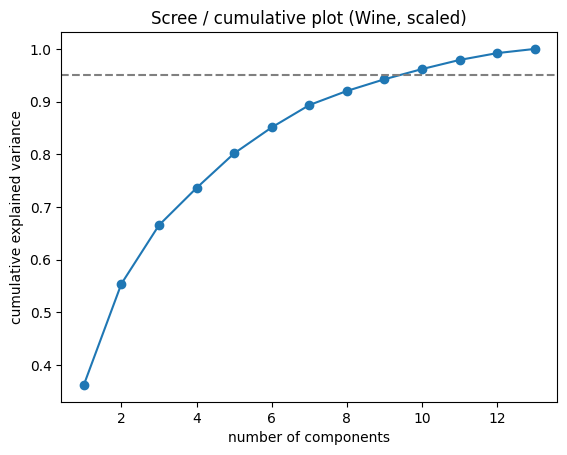

In [68]:
scaled = PCA().fit(StandardScaler().fit_transform(Xw))
print('WITH scaling, first 3 ratios:', scaled.explained_variance_ratio_[:3].round(4))
cum = np.cumsum(scaled.explained_variance_ratio_)
plt.plot(range(1, 14), cum, 'o-'); plt.axhline(0.95, ls='--', c='gray')
plt.xlabel('number of components'); plt.ylabel('cumulative explained variance'); plt.title('Scree / cumulative plot (Wine, scaled)')
plt.show()

### Student Practice 3
1. How many components are needed to reach 95% variance on scaled Wine?
2. In the lecture's PCA steps, which step did the unscaled run skip?

In [69]:
# your code here
wine = load_wine()
X = wine.data
X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
pca.fit(X_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
print("Cumulative explained variance:")
print(cumulative_variance)
n_components = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed for 95% variance:", n_components)

Cumulative explained variance:
[0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]
Components needed for 95% variance: 10


# Mini Project A: PCA on Digits (Image Track — continuing from Weeks 7 and 8)
Same split as before (`test_size=0.3, random_state=1, stratify`). Baselines you already have: **KNN (scaled, K=3) = 0.9796** and **Tree (entropy, full depth, unscaled) = 0.8815**. Question: how many of the 64 pixels-worth of information do we really need?

In [70]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
sc = StandardScaler().fit(Xd_train)                 # fit on TRAIN only
Xtr, Xte = sc.transform(Xd_train), sc.transform(Xd_test)
pca = PCA().fit(Xtr)                                # fit on TRAIN only
cum = np.cumsum(pca.explained_variance_ratio_)
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'{int(t*100)}% variance needs', int(np.argmax(cum >= t)) + 1, 'of 64 components')

80% variance needs 21 of 64 components
90% variance needs 31 of 64 components
95% variance needs 40 of 64 components
99% variance needs 54 of 64 components


### Predict-then-run
How many components for 90% of the variance? Guess: ~5 / ~15 / ~30 / ~55. And what will KNN accuracy look like with only 10 components?

### Student Practice 4
1. For k in [2, 5, 10, 20, 30, 40, 64] fit PCA(k) on `Xtr`, transform train and test, and report KNN (K=3) and Tree (entropy, random_state=1) test accuracy.
2. Which k values give KNN within 0.5 percentage points of the full-pixel baseline 0.9796?
3. Does the tree improve, stay the same, or get worse with PCA features compared with its raw-pixel 0.8815? Why might that be? (Think: what do tree splits do to axes?)

In [71]:
# Q1-Q3: your code here
digits = load_digits()
X = digits.data
y = digits.target
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
ks = [2, 5, 10, 20, 30, 40, 64]
results = []
for k in ks:
    pca = PCA(n_components=k)
    Xtr_pca = pca.fit_transform(Xtr)
    Xte_pca = pca.transform(Xte)
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(Xtr_pca, ytr)
    knn_acc = accuracy_score(yte, knn.predict(Xte_pca))
    tree = DecisionTreeClassifier(criterion="entropy", random_state=1)
    tree.fit(Xtr_pca, ytr)
    tree_acc = accuracy_score(yte, tree.predict(Xte_pca))
    results.append([k, round(knn_acc, 4), round(tree_acc, 4)])
df = pd.DataFrame(results,columns=["Components (k)", "KNN Accuracy", "Tree Accuracy"])
print(df.to_string(index=False))
baseline = 0.9796
print("\nKNN k values within 0.5 percentage points:")
print(df[df["KNN Accuracy"] >= baseline - 0.005]["Components (k)"].tolist())

 Components (k)  KNN Accuracy  Tree Accuracy
              2        0.6000         0.5528
              5        0.9361         0.8500
             10        0.9806         0.8528
             20        0.9833         0.8722
             30        0.9778         0.8722
             40        0.9806         0.8639
             64        0.9833         0.8583

KNN k values within 0.5 percentage points:
[10, 20, 30, 40, 64]


### Look at the components
Each principal component is a 64-number vector, i.e. an 8×8 image.

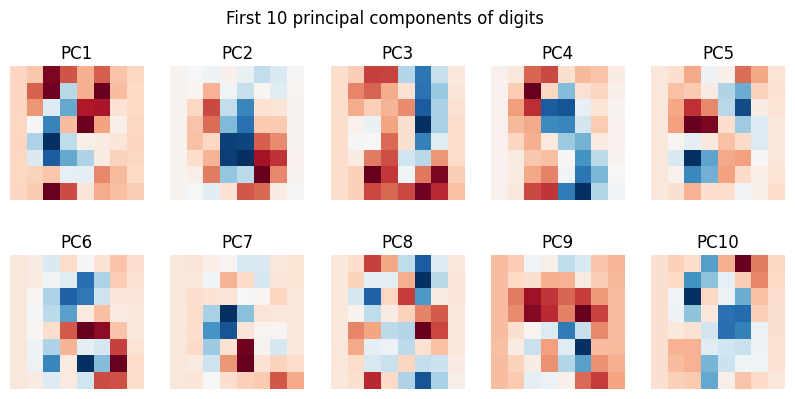

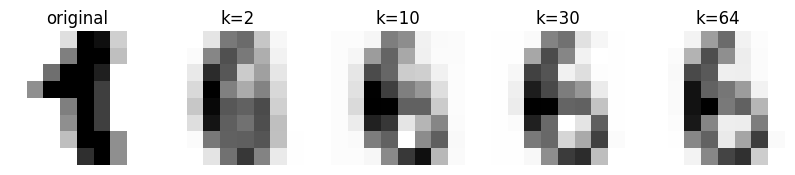

In [72]:
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.ravel()):
    a.imshow(pca.components_[i].reshape(8, 8), cmap='RdBu'); a.set_title(f'PC{i+1}'); a.axis('off')
plt.suptitle('First 10 principal components of digits'); plt.show()

# reconstruction of one digit from k components
k_list = [2, 10, 30, 64]
fig, ax = plt.subplots(1, 5, figsize=(10, 2.5))
ax[0].imshow(Xd_test[0].reshape(8, 8), cmap='gray_r'); ax[0].set_title('original'); ax[0].axis('off')
for a, k in zip(ax[1:], k_list):
    pk = PCA(k).fit(Xtr)
    rec = sc.inverse_transform(pk.inverse_transform(pk.transform(Xte[:1])))
    a.imshow(rec.reshape(8, 8), cmap='gray_r'); a.set_title(f'k={k}'); a.axis('off')
plt.show()

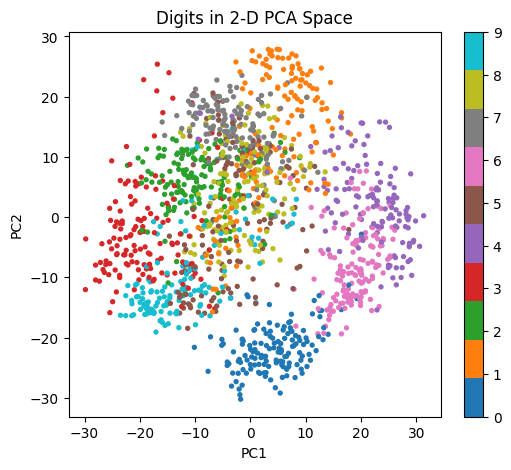

In [73]:
# 2-D view: can two components separate the ten digits?
Z2 = PCA(n_components=2).fit_transform(Xtr)
plt.figure(figsize=(6, 5))
sc_ = plt.scatter(Z2[:, 0], Z2[:, 1],c=ytr, cmap='tab10', s=8)
plt.colorbar(sc_)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Digits in 2-D PCA Space')
plt.show()

### Deliberate error: fitting PCA on all the data
Run the cell below, then answer: why is this wrong even if the accuracy looks fine?

In [74]:
scaler_all = StandardScaler().fit(digits.data)           # WRONG: sees test rows
p_all = PCA(30).fit(scaler_all.transform(digits.data))   # WRONG
a = p_all.transform(scaler_all.transform(Xd_train)); b = p_all.transform(scaler_all.transform(Xd_test))
print('leaky KNN k=30:', KNeighborsClassifier(3).fit(a, yd_train).score(b, yd_test))

leaky KNN k=30: 0.9777777777777777


# Mini Project B: PCA on the Six Sentences (NLP Track — continuing from Weeks 7 and 8)
Same sentences and bag-of-words vectors. Question: can a 2-D picture show the three topics?

In [75]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']
vocab = sorted(set(w for s in sentences for w in s.lower().split()))
X_text = np.array([[s.lower().split().count(w) for w in vocab] for s in sentences])
print('matrix shape (docs x vocab):', X_text.shape)

matrix shape (docs x vocab): (6, 29)


### Predict-then-run
The matrix has 6 rows and 29 columns. (a) What is the maximum number of non-zero principal components? (b) Will 2 components capture >90% of variance?

### Student Practice 5
1. Fit `PCA(2)` on `X_text` (no scaling, counts are already comparable). Print `explained_variance_ratio_` and its sum.
2. Scatter-plot the 6 points, colour by label, annotate with the sentence number.
3. Do same-topic sentences land near each other? Which pair does PCA place closest?
4. Print the 5 words with the largest absolute weight on PC1 and PC2.

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from itertools import combinations
from scipy.spatial.distance import euclidean
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_text)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Sum of explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.2642 0.2088]
Sum of explained variance: 0.4730751133209796


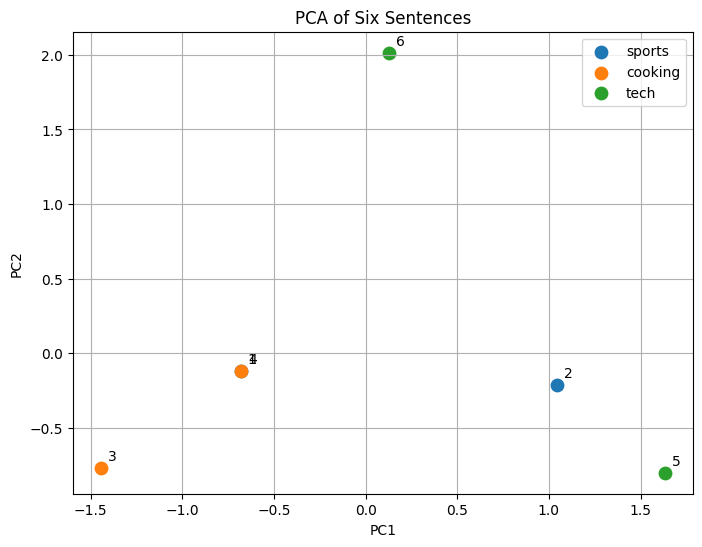

In [77]:
plt.figure(figsize=(8, 6))
for label in set(labels):
    idx = np.array(labels) == label
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=label, s=80)
for i, (x, y) in enumerate(X_pca):
    plt.annotate(str(i + 1), (x, y), xytext=(5, 5),textcoords="offset points")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Six Sentences")
plt.legend()
plt.grid(True)
plt.show()

In [78]:
pairs = [(euclidean(X_pca[i], X_pca[j]), i, j)
    for i, j in combinations(range(len(X_pca)), 2)]
distance, i, j = min(pairs)
print(f"Closest pair: Sentences {i + 1} and {j + 1}")
print(f"Distance: {distance:.4f}")
print("Same topic?", labels[i] == labels[j])

Closest pair: Sentences 1 and 4
Distance: 0.0000
Same topic? False


In [79]:
for component, name in enumerate(["PC1", "PC2"]):
    loadings = pca.components_[component]
    top_indices = np.argsort(np.abs(loadings))[::-1][:5]
    print(f"\nTop 5 words for {name}:")
    for idx in top_indices:
        print(f"{vocab[idx]}: {loadings[idx]:.4f}")


Top 5 words for PC1:
a: 0.3946
and: -0.3133
the: -0.3133
processor: 0.2405
new: 0.2405

Top 5 words for PC2:
all: 0.3758
laptop: 0.3758
day: 0.3758
lasts: 0.3758
battery: 0.3758


## Part 6: Reflection (write 2–3 lines each)
1. In your own words: what does PCA keep and what does it throw away?
2. Why must we standardize before PCA? Give the Wine evidence.
3. Digits: pick the k you would deploy and justify (accuracy vs. size).
4. PCA helped KNN but not the tree. What does this say about when to use PCA?
5. PCA is **unsupervised**; it never looked at the labels. What could go wrong? (This sets up LDA, the next topic in Unit II.)
6. **Capstone link (Milestone, Week 9):** will PCA belong in your pipeline? If yes, show the cumulative-variance plot and the accuracy-vs-k table in your repo's `notebooks/` folder; if no, justify.

*Submit this notebook to GitHub under `labs/week9_pca/`.*